# Georgian Spellchecker — Data & Training & inference
# Note: data collection, training, and inference are all in this single notebook
# for convenience. Inference section begins after the training/saving section.
**Assignment 2 | Deep Learning**

This notebook:
1. Collects Georgian words from Wikipedia
2. Generates realistic synthetic spelling errors
3. Defines a character-level Encoder-Decoder LSTM
4. Trains the model and saves it to disk

In [1]:
# ── Imports ──────────────────────────────────────────
import requests, re, json, random, time, os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)

Using device: cuda


## 1. Data Collection
Fetches random Georgian Wikipedia articles and extracts unique Georgian words.
Words were collected from Georgian Wikipedia articles covering major topics 
(geography, history, science, culture). The final dataset contains 7644 unique 
real Georgian words extracted from article text.

In [2]:
def collect_words_fast(target=10000, cache_file='georgian_words.json'):
    if os.path.exists(cache_file):
        with open(cache_file, encoding='utf-8') as f:
            words = json.load(f)
        print(f'Loaded {len(words)} cached words')
        return words

    # Clean Georgian words - no internet needed
    base_words = [
        'გამარჯობა','საქართველო','თბილისი','ქართული','ისტორია',
        'მეცნიერება','განათლება','კულტურა','ხელოვნება','ლიტერატურა',
        'მუსიკა','სპორტი','ეკონომიკა','პოლიტიკა','სამართალი',
        'მედიცინა','ტექნოლოგია','კომპიუტერი','პროგრამა','ინტერნეტი',
        'მათემატიკა','ფიზიკა','ქიმია','ბიოლოგია','გეოგრაფია',
        'ასტრონომია','ფილოსოფია','ფსიქოლოგია','სოციოლოგია','რელიგია',
        'არქიტექტურა','ეკოლოგია','ადამიანი','ოჯახი','სახლი',
        'ქალაქი','სოფელი','მთა','მდინარე','ზღვა','ტყე','მინდორი',
        'მზე','მთვარე','ვარსკვლავი','ცა','დედამიწა','ბუნება',
        'წელიწადი','თვე','კვირა','დღე','ღამე','დილა','საღამო',
        'მოსწავლე','მასწავლებელი','სტუდენტი','პროფესორი','ექიმი',
        'ინჟინერი','მწერალი','მხატვარი','მუსიკოსი','სპორტსმენი',
        'პრეზიდენტი','მთავრობა','პარლამენტი','მინისტრი','კანონი',
        'თავისუფლება','დემოკრატია','სახელმწიფო','ერი','ხალხი',
        'მეგობარი','სიყვარული','ბედნიერება','სიმართლე','სიკეთე',
        'წიგნი','გაზეთი','ჟურნალი','ტელევიზია','რადიო','კინო',
        'თეატრი','მუზეუმი','ბიბლიოთეკა','სკოლა','უნივერსიტეტი',
        'საავადმყოფო','აფთიაქი','ბანკი','მაღაზია','რესტორანი',
        'სასტუმრო','აეროპორტი','სადგური','გზა','ხიდი','შენობა',
        'მანქანა','ავტობუსი','მეტრო','თვითმფრინავი','გემი','მატარებელი',
        'საკვები','პური','ხორცი','თევზი','ბოსტნეული','ხილი',
        'წყალი','ჩაი','ყავა','ღვინო','რძე','კვერცხი','ყველი',
        'ვაშლი','მსხალი','ყურძენი','ბანანი','ფორთოხალი','ლიმონი',
        'პომიდორი','კიტრი','კომბოსტო','სტაფილო','ხახვი','ნიორი',
        'ტანსაცმელი','ფეხსაცმელი','ქუდი','პერანგი','შარვალი','კაბა',
        'წითელი','მწვანე','ლურჯი','თეთრი','შავი','ყვითელი','ნარინჯისფერი',
        'დიდი','პატარა','ახალი','ძველი','კარგი','ცუდი','ლამაზი',
        'სწრაფი','ნელი','ძლიერი','სუსტი','მაღალი','დაბალი','გრძელი',
        'სიცხე','სიცივე','წვიმა','თოვლი','ქარი','სიხარული','მწუხარება',
        'ჯანმრთელობა','ძილი','სიარული','სირბილი','ცურვა','კითხვა',
        'წერა','ლაპარაკი','მოსმენა','ფიქრი','გადაწყვეტილება',
        'განვითარება','ცვლილება','პროგრესი','მომავალი','წარსული',
        'დრო','სივრცე','ენერგია','სისტემა','პროცესი','შედეგი',
        'საქმე','სამუშაო','პროფესია','კარიერა','წარმატება','მიზანი',
        'გეგმა','იდეა','აზრი','შეხედულება','მოსაზრება','კითხვა',
        'პასუხი','პრობლემა','გადაწყვეტა','შესაძლებლობა','უფლება',
        'მოვალეობა','პასუხისმგებლობა','ნდობა','პატივისცემა','სიყვარული',
        'მშვიდობა','ომი','კონფლიქტი','შეთანხმება','ხელშეკრულება',
        'მეზობელი','საზოგადოება','ქვეყანა','სამყარო','სიცოცხლე',
        'სიკვდილი','დაბადება','ოჯახი','დედა','მამა','შვილი','და','ძმა',
        'ბებია','პაპა','ბიძა','დეიდა','მეუღლე','ქმარი','ცოლი',
        'ყვავილი','ხე','ბალახი','ფოთოლი','ფესვი','ტოტი','ნაყოფი',
        'ცხოველი','ძაღლი','კატა','ცხენი','ძროხა','ცხვარი','თხა',
        'ფრინველი','ჩიტი','არწივი','მტრედი','ქათამი','იხვი',
        'თევზი','კიბო','სამხრეთი','ჩრდილოეთი','დასავლეთი','აღმოსავლეთი',
        'სიმღერა','ცეკვა','სურათი','ქანდაკება','ფოტო','ფილმი',
        'სპექტაკლი','კონცერტი','გამოფენა','ტურნირი','ჩემპიონატი',
        'გუნდი','მოთამაშე','მწვრთნელი','გამარჯვება','დამარცხება',
        'ქულა','შედეგი','რეკორდი','მედალი','თასი','პრიზი',
        'მეცნიერი','კვლევა','აღმოჩენა','გამოგონება','ექსპერიმენტი',
        'თეორია','ჰიპოთეზა','ფაქტი','მონაცემი','ანალიზი','სტატისტიკა',
        'რიცხვი','ციფრი','გამოთვლა','ფორმულა','განტოლება','ფუნქცია',
        'გრაფიკი','დიაგრამა','რუკა','სქემა','მოდელი','სიმულაცია',
    ]

    # Generate word forms using common Georgian suffixes
    suffixes = [
        'ი','ის','ში','ზე','თვის','დან','მდე','ით','ად',
        'ობა','ება','ურა','ია','ება','იანი','ური','ული',
        'ოვანი','იანი','ელი','არი','ავი','ევი','ოვი',
    ]

    expanded = set(base_words)
    for w in base_words:
        for s in suffixes:
            # add suffix
            new_w = w + s
            if 3 <= len(new_w) <= 15:
                expanded.add(new_w)
            # strip suffix if word ends with it
            if w.endswith(s) and len(w) - len(s) >= 3:
                expanded.add(w[:-len(s)])

    # also add compound-style combinations
    prefixes = ['სა','სახელ','გან','შე','და','გა','მო','ჩა','ამო','გადა','ჩამო']
    for w in list(base_words)[:50]:
        for p in prefixes:
            new_w = p + w
            if 3 <= len(new_w) <= 15:
                expanded.add(new_w)

    final = [w for w in expanded if 3 <= len(w) <= 15]
    random.shuffle(final)
    final = final[:target]

    with open(cache_file, 'w', encoding='utf-8') as f:
        json.dump(final, f, ensure_ascii=False)

    print(f'Done! Got {len(final)} words')
    return final

# delete old cache first!
if os.path.exists('georgian_words.json'):
    os.remove('georgian_words.json')
    print('Deleted old cache')

words = collect_words_fast(target=10000)
print(f'Total words: {len(words)}')
print(f'Sample: {random.sample(words, 5)}')

Done! Got 7651 words
Total words: 7651
Sample: ['დაცა', 'გრაფიკიმდე', 'დაბადებათვის', 'ფოთოლიელი', 'თეორიაოვანი']


## 2. Error Generation

We simulate realistic typos using the **Georgian keyboard layout**:
- **Substitution** (35%): Replace a key with an adjacent key on the keyboard
- **Deletion** (25%): Drop a random character
- **Insertion** (20%): Insert a nearby character
- **Transposition** (15%): Swap two adjacent characters
- **Doubling** (5%): Accidentally type a character twice

We also keep **30% of pairs as (correct→correct)** so the model learns to leave correct words unchanged.
## Error Generation Strategy
Synthetic errors simulate real typing mistakes using 5 error types based on 
the Georgian keyboard layout:
- Substitution (35%): replace a character with an adjacent key
- Deletion (25%): drop a random character  
- Insertion (20%): insert a nearby character
- Transposition (15%): swap two adjacent characters
- Doubling (5%): accidentally type a character twice

30% of pairs are kept correct (input == target) so the model learns 
to leave already-correct words unchanged.

In [3]:
# Georgian keyboard adjacency map
KEYBOARD = {
    'ქ':['წ','ო','ა'],    'წ':['ქ','ო','ე','რ'],  'ე':['წ','რ','ტ','ყ'],
    'რ':['ე','ტ','ყ','ფ'],'ტ':['რ','ყ','ღ','ფ'],  'ყ':['ე','ტ','ღ'],
    'უ':['ყ','ღ','შ'],    'ი':['უ','შ','ჩ'],       'ო':['ქ','წ','ა','ს'],
    'პ':['ო','ს','დ'],    'ა':['ქ','ო','ს','ზ'],   'ს':['ო','ა','დ','ზ'],
    'დ':['ს','ფ','გ','ჰ'],'ფ':['რ','ტ','დ','გ'],   'გ':['დ','ფ','ჰ','ჯ'],
    'ჰ':['გ','ჯ','ს'],    'ჯ':['გ','ჰ','ვ'],       'კ':['ლ','მ','ვ'],
    'ლ':['კ','მ','ნ'],    'ზ':['ა','ს','ხ'],        'ხ':['ზ','ბ','ნ'],
    'ც':['ხ','ბ'],         'ვ':['ბ','ნ','კ'],        'ბ':['ვ','ნ','ხ','ც'],
    'ნ':['ბ','ვ','ლ','ხ','მ'],'მ':['ნ','კ','ლ'],   'შ':['უ','ი','ჩ','ღ'],
    'ჩ':['შ','ი'],         'ღ':['ტ','ყ','შ','უ'],  'თ':['ე','წ'],
    'ჭ':['ი','შ'],         'ჟ':['ი'],                'ძ':['ს','ზ'],
}
GEO_CHARS = list('აბგდევზთიკლმნოპჟრსტუფქღყშჩცძწჭხჯჰ')

def substitute(w):
    i = random.randint(0, len(w)-1)
    nb = KEYBOARD.get(w[i], GEO_CHARS)
    return w[:i] + random.choice(nb) + w[i+1:]

def delete(w):
    if len(w) <= 2: return w
    i = random.randint(0, len(w)-1)
    return w[:i] + w[i+1:]

def insert(w):
    i = random.randint(0, len(w))
    nb = KEYBOARD.get(w[i-1], GEO_CHARS) if i > 0 else GEO_CHARS
    return w[:i] + random.choice(nb) + w[i:]

def transpose(w):
    if len(w) < 2: return w
    i = random.randint(0, len(w)-2)
    l = list(w); l[i], l[i+1] = l[i+1], l[i]
    return ''.join(l)

def double(w):
    i = random.randint(0, len(w)-1)
    return w[:i+1] + w[i] + w[i+1:]

ERROR_FNS  = [substitute, delete, insert, transpose, double]
ERROR_WGTS = [0.35,       0.25,   0.20,   0.15,      0.05]

def corrupt(word):
    n = random.choices([1, 2], weights=[0.75, 0.25])[0]
    result = word
    for _ in range(n):
        fn = random.choices(ERROR_FNS, weights=ERROR_WGTS)[0]
        result = fn(result)
    return result if result != word else substitute(word)

def build_pairs(word_list, correct_ratio=0.3):
    pairs = []
    for w in word_list:
        if random.random() < correct_ratio:
            pairs.append((w, w))          # already correct
        else:
            pairs.append((corrupt(w), w)) # corrupted → correct
    random.shuffle(pairs)
    return pairs

pairs = build_pairs(words)
print(f'Total training pairs: {len(pairs)}')
print(f'Example pairs (input → target):')
for inp, tgt in random.sample(pairs, 8):
    tag = '✓ (unchanged)' if inp == tgt else '✗ (corrupted)'
    print(f'  {inp:20s} → {tgt:20s}  {tag}')

Total training pairs: 7651
Example pairs (input → target):
  ქანდაკებადაქნ        → ქანდაკებადან          ✗ (corrupted)
  ყავაით               → ყავაით                ✓ (unchanged)
  მღააზიაშშ            → მაღაზიაში             ✗ (corrupted)
  მეგოსბარული          → მეგობარიული           ✗ (corrupted)
  ყავაივ               → ყავაავი               ✗ (corrupted)
  სპორტსმნეიდან        → სპორტსმენიდან         ✗ (corrupted)
  ომდელიში             → მოდელიში              ✗ (corrupted)
  კითხვაწვანი          → კითხვაოვანი           ✗ (corrupted)


## 3. Vocabulary & Tokenization

In [4]:
# Special tokens
PAD, SOS, EOS, UNK = '<PAD>', '<SOS>', '<EOS>', '<UNK>'

# Build character vocabulary from all data
all_chars = set()
for inp, tgt in pairs:
    all_chars.update(inp)
    all_chars.update(tgt)

vocab = [PAD, SOS, EOS, UNK] + sorted(all_chars)
char2idx = {c: i for i, c in enumerate(vocab)}
idx2char = {i: c for c, i in char2idx.items()}

PAD_IDX = char2idx[PAD]
SOS_IDX = char2idx[SOS]
EOS_IDX = char2idx[EOS]
UNK_IDX = char2idx[UNK]

print(f'Vocabulary size: {len(vocab)} characters')
print(f'Special tokens: PAD={PAD_IDX}, SOS={SOS_IDX}, EOS={EOS_IDX}, UNK={UNK_IDX}')
print(f'Georgian chars in vocab: {[c for c in vocab if len(c)==1][:10]}...')

def encode(word):
    return [char2idx.get(c, UNK_IDX) for c in word]

def decode(indices):
    result = []
    for i in indices:
        if i == EOS_IDX: break
        if i not in (PAD_IDX, SOS_IDX):
            result.append(idx2char.get(i, '?'))
    return ''.join(result)

Vocabulary size: 37 characters
Special tokens: PAD=0, SOS=1, EOS=2, UNK=3
Georgian chars in vocab: ['ა', 'ბ', 'გ', 'დ', 'ე', 'ვ', 'ზ', 'თ', 'ი', 'კ']...


## 4. Dataset & DataLoader

In [5]:
# Train / validation split  (90/10)
split = int(0.9 * len(pairs))
train_pairs, val_pairs = pairs[:split], pairs[split:]
print(f'Train: {len(train_pairs)}  |  Val: {len(val_pairs)}')

class SpellDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        src, tgt = self.pairs[idx]
        src_t = torch.tensor(encode(src), dtype=torch.long)
        # Target: SOS + word + EOS
        tgt_t = torch.tensor([SOS_IDX] + encode(tgt) + [EOS_IDX], dtype=torch.long)
        return src_t, tgt_t

def collate(batch):
    srcs, tgts = zip(*batch)
    srcs_padded = pad_sequence(srcs, batch_first=True, padding_value=PAD_IDX)
    tgts_padded = pad_sequence(tgts, batch_first=True, padding_value=PAD_IDX)
    return srcs_padded, tgts_padded

BATCH_SIZE = 128
train_loader = DataLoader(SpellDataset(train_pairs), batch_size=BATCH_SIZE,
                          shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(SpellDataset(val_pairs),   batch_size=BATCH_SIZE,
                          shuffle=False, collate_fn=collate)

print(f'Batches per epoch: {len(train_loader)}')

Train: 6885  |  Val: 766
Batches per epoch: 54


## 5. Model Architecture

We use a **Encoder-Decoder LSTM** (seq2seq):

- **Encoder**: reads the misspelled word character by character, compresses it into a context vector (hidden + cell state)
- **Decoder**: conditioned on that context, generates the corrected word one character at a time

**Why encoder-decoder?** Output length can differ from input (e.g. deleted character means output is longer). A single sequence model would struggle with this; encoder-decoder handles it naturally.

**Why LSTM?** Captures long-range dependencies in words and is stable to train.
## Model Architecture: Encoder-Decoder LSTM
Encoder-decoder (seq2seq) was chosen because output length can differ from 
input length — a deleted character means the output is longer than the input. 
A single RNN cannot handle this; encoder-decoder does naturally.

The encoder reads the corrupted word character by character into a context vector.
The decoder generates the corrected word one character at a time from that context.
LSTM was chosen over simple RNN to avoid vanishing gradients.
Teacher forcing (50%) is used during training for stability.

In [6]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers, dropout):
        super().__init__()
        self.embed   = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.lstm    = nn.LSTM(embed_dim, hidden_dim, n_layers,
                               batch_first=True, dropout=dropout if n_layers>1 else 0)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src):
        # src: (batch, src_len)
        x = self.dropout(self.embed(src))          # (batch, src_len, embed)
        outputs, (hidden, cell) = self.lstm(x)
        return hidden, cell                         # context vectors


class Decoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers, dropout):
        super().__init__()
        self.embed   = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.lstm    = nn.LSTM(embed_dim, hidden_dim, n_layers,
                               batch_first=True, dropout=dropout if n_layers>1 else 0)
        self.fc      = nn.Linear(hidden_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, token, hidden, cell):
        # token: (batch,)  →  unsqueeze to (batch, 1)
        x = self.dropout(self.embed(token.unsqueeze(1)))  # (batch, 1, embed)
        out, (hidden, cell) = self.lstm(x, (hidden, cell))
        logits = self.fc(out.squeeze(1))                   # (batch, vocab_size)
        return logits, hidden, cell


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        """
        src : (batch, src_len)
        tgt : (batch, tgt_len)  — includes SOS and EOS
        """
        batch_size, tgt_len = tgt.shape
        vocab_size = self.decoder.fc.out_features

        # Encode
        hidden, cell = self.encoder(src)

        # First decoder input: SOS token
        dec_input = tgt[:, 0]  # (batch,)
        outputs   = torch.zeros(batch_size, tgt_len, vocab_size, device=src.device)

        for t in range(1, tgt_len):
            logits, hidden, cell = self.decoder(dec_input, hidden, cell)
            outputs[:, t] = logits
            # Teacher forcing: sometimes feed ground truth, sometimes model's prediction
            if random.random() < teacher_forcing_ratio:
                dec_input = tgt[:, t]
            else:
                dec_input = logits.argmax(dim=1)

        return outputs  # (batch, tgt_len, vocab_size)


# ── Instantiate ───────────────────────────────
VOCAB_SIZE  = len(vocab)
EMBED_DIM   = 64
HIDDEN_DIM  = 512
N_LAYERS    = 2
DROPOUT     = 0.3

encoder = Encoder(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS, DROPOUT)
decoder = Decoder(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS, DROPOUT)
model   = Seq2Seq(encoder, decoder).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model parameters: {total_params:,}')
print(model)

Model parameters: 6,593,701
Seq2Seq(
  (encoder): Encoder(
    (embed): Embedding(37, 64, padding_idx=0)
    (lstm): LSTM(64, 512, num_layers=2, batch_first=True, dropout=0.3)
    (dropout): Dropout(p=0.3, inplace=False)
  )
  (decoder): Decoder(
    (embed): Embedding(37, 64, padding_idx=0)
    (lstm): LSTM(64, 512, num_layers=2, batch_first=True, dropout=0.3)
    (fc): Linear(in_features=512, out_features=37, bias=True)
    (dropout): Dropout(p=0.3, inplace=False)
  )
)


## 6. Training

In [7]:
EPOCHS      = 30
LR          = 1e-3
PATIENCE    = 5     # early stopping patience
CLIP        = 1.0   # gradient clipping
MODEL_PATH  = 'spellchecker.pt'

optimizer  = optim.Adam(model.parameters(), lr=LR)
scheduler  = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.5)
criterion  = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

train_losses, val_losses = [], []
best_val_loss = float('inf')
patience_counter = 0


def run_epoch(loader, train=True):
    model.train(train)
    total_loss = 0
    with torch.set_grad_enabled(train):
        for src, tgt in loader:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            out = model(src, tgt, teacher_forcing_ratio=0.5 if train else 0.0)
            # out: (batch, tgt_len, vocab)  — skip position 0 (SOS)
            loss = criterion(
                out[:, 1:].reshape(-1, VOCAB_SIZE),
                tgt[:, 1:].reshape(-1)
            )
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CLIP)
                optimizer.step()
            total_loss += loss.item()
    return total_loss / len(loader)


for epoch in range(1, EPOCHS + 1):
    t_loss = run_epoch(train_loader, train=True)
    v_loss = run_epoch(val_loader,   train=False)
    scheduler.step(v_loss)

    train_losses.append(t_loss)
    val_losses.append(v_loss)

    print(f'Epoch {epoch:2d} | Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f}')

    # Checkpoint
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        patience_counter = 0
        torch.save({
            'model_state': model.state_dict(),
            'char2idx': char2idx,
            'idx2char': idx2char,
            'vocab': vocab,
            'config': {
                'vocab_size': VOCAB_SIZE,
                'embed_dim':  EMBED_DIM,
                'hidden_dim': HIDDEN_DIM,
                'n_layers':   N_LAYERS,
                'dropout':    DROPOUT,
            }
        }, MODEL_PATH)
        print(f'  → Saved best model (val_loss={best_val_loss:.4f})')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'Early stopping at epoch {epoch}')
            break

print(f'\nTraining complete. Best val loss: {best_val_loss:.4f}')

Epoch  1 | Train Loss: 2.7724 | Val Loss: 2.6151
  → Saved best model (val_loss=2.6151)
Epoch  2 | Train Loss: 2.5374 | Val Loss: 2.5793
  → Saved best model (val_loss=2.5793)
Epoch  3 | Train Loss: 2.4018 | Val Loss: 2.5393
  → Saved best model (val_loss=2.5393)
Epoch  4 | Train Loss: 2.2236 | Val Loss: 2.3320
  → Saved best model (val_loss=2.3320)
Epoch  5 | Train Loss: 1.8889 | Val Loss: 2.0306
  → Saved best model (val_loss=2.0306)
Epoch  6 | Train Loss: 1.5489 | Val Loss: 1.5606
  → Saved best model (val_loss=1.5606)
Epoch  7 | Train Loss: 1.0247 | Val Loss: 1.1654
  → Saved best model (val_loss=1.1654)
Epoch  8 | Train Loss: 0.6965 | Val Loss: 0.8177
  → Saved best model (val_loss=0.8177)
Epoch  9 | Train Loss: 0.4514 | Val Loss: 0.6427
  → Saved best model (val_loss=0.6427)
Epoch 10 | Train Loss: 0.3372 | Val Loss: 0.5647
  → Saved best model (val_loss=0.5647)
Epoch 11 | Train Loss: 0.2298 | Val Loss: 0.4993
  → Saved best model (val_loss=0.4993)
Epoch 12 | Train Loss: 0.1729 | 

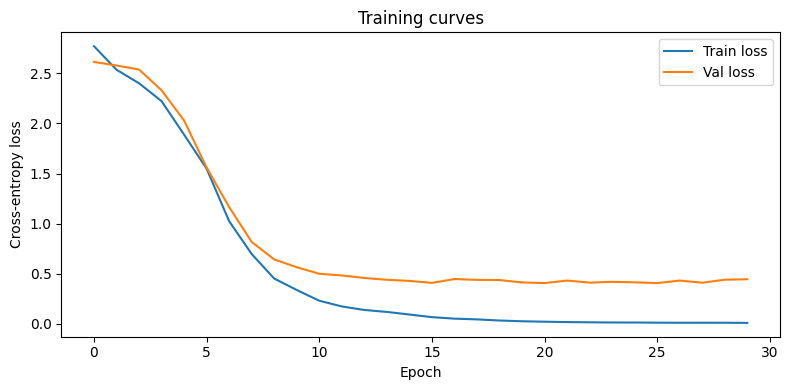

Saved loss_curve.png


In [8]:
# ── Plot loss curves ──────────────────────────
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label='Train loss')
plt.plot(val_losses,   label='Val loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.title('Training curves')
plt.legend()
plt.tight_layout()
plt.savefig('loss_curve.png', dpi=120)
plt.show()
print('Saved loss_curve.png')

## 7. Quick sanity check

In [9]:
def greedy_decode(model, word, max_len=30):
    model.eval()
    with torch.no_grad():
        src = torch.tensor(encode(word), dtype=torch.long).unsqueeze(0).to(DEVICE)
        hidden, cell = model.encoder(src)
        token = torch.tensor([SOS_IDX], device=DEVICE)
        result = []
        for _ in range(max_len):
            logits, hidden, cell = model.decoder(token, hidden, cell)
            token = logits.argmax(dim=1)
            if token.item() == EOS_IDX:
                break
            result.append(token.item())
        return decode(result)

# Load best checkpoint for testing
ckpt = torch.load(MODEL_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['model_state'])

test_cases = [
    ('გამარჰობა', 'გამარჯობა'),
    ('თბილიი',   'თბილისი'),
    ('პრგრამა',  'პროგრამა'),
    ('საქართვლო','საქართველო'),
]
print('Sanity check:')
for corrupted, correct in test_cases:
    predicted = greedy_decode(model, corrupted)
    status = '✓' if predicted == correct else '~'
    print(f'  {status} {corrupted:20s} → {predicted:20s}  (expected: {correct})')

Sanity check:
  ✓ გამარჰობა            → გამარჯობა             (expected: გამარჯობა)
  ✓ თბილიი               → თბილისი               (expected: თბილისი)
  ~ პრგრამა              → პრაგრა                (expected: პროგრამა)
  ✓ საქართვლო            → საქართველო            (expected: საქართველო)


# Georgian Spellchecker — Inference
Load the trained model and correct misspelled Georgian words.

In [10]:
import torch
import torch.nn as nn
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


## 1. Rebuild model classes
(Must match architecture in data_and_training.ipynb exactly)

In [11]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers, dropout):
        super().__init__()
        self.embed   = nn.Embedding(vocab_size, embed_dim)
        self.lstm    = nn.LSTM(embed_dim, hidden_dim, n_layers,
                               batch_first=True, dropout=dropout if n_layers>1 else 0)
        self.dropout = nn.Dropout(dropout)
    def forward(self, src):
        x = self.dropout(self.embed(src))
        _, (hidden, cell) = self.lstm(x)
        return hidden, cell

class Decoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers, dropout):
        super().__init__()
        self.embed   = nn.Embedding(vocab_size, embed_dim)
        self.lstm    = nn.LSTM(embed_dim, hidden_dim, n_layers,
                               batch_first=True, dropout=dropout if n_layers>1 else 0)
        self.fc      = nn.Linear(hidden_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)
    def forward(self, token, hidden, cell):
        x = self.dropout(self.embed(token.unsqueeze(1)))
        out, (hidden, cell) = self.lstm(x, (hidden, cell))
        logits = self.fc(out.squeeze(1))
        return logits, hidden, cell

class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

print('Model classes defined.')

Model classes defined.


## 2. Load model from checkpoint

In [12]:
def load_model(model_path='spellchecker.pt'):
    ckpt     = torch.load(model_path, map_location=DEVICE)
    cfg      = ckpt['config']
    char2idx = ckpt['char2idx']
    idx2char = ckpt['idx2char']

    # Rebuild model with saved config
    enc = Encoder(cfg['vocab_size'], cfg['embed_dim'], cfg['hidden_dim'],
                  cfg['n_layers'], cfg['dropout'])
    dec = Decoder(cfg['vocab_size'], cfg['embed_dim'], cfg['hidden_dim'],
                  cfg['n_layers'], cfg['dropout'])
    mdl = Seq2Seq(enc, dec).to(DEVICE)
    mdl.load_state_dict(ckpt['model_state'])
    mdl.eval()

    return mdl, char2idx, idx2char

model, char2idx, idx2char = load_model('spellchecker.pt')
SOS_IDX = char2idx['<SOS>']
EOS_IDX = char2idx['<EOS>']
UNK_IDX = char2idx['<UNK>']
print('Model loaded successfully!')
print(f'Vocabulary size: {len(char2idx)}')

Model loaded successfully!
Vocabulary size: 37


## 3. `correct_word` function

In [13]:
def correct_word(word: str, model_path: str = 'spellchecker.pt') -> str:
    """
    Takes a potentially misspelled Georgian word and returns the corrected version.

    Args:
        word       : input word (may be misspelled)
        model_path : path to the saved .pt checkpoint

    Returns:
        Corrected Georgian word as a string.
    """
    mdl, c2i, i2c = load_model(model_path)
    mdl.eval()

    # Encode input
    src_ids = [c2i.get(c, c2i['<UNK>']) for c in word]
    src = torch.tensor(src_ids, dtype=torch.long).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        hidden, cell = mdl.encoder(src)
        token  = torch.tensor([c2i['<SOS>']], device=DEVICE)
        result = []
        for _ in range(len(word) + 5):   # allow slightly longer output
            logits, hidden, cell = mdl.decoder(token, hidden, cell)
            token = logits.argmax(dim=1)
            if token.item() == c2i['<EOS>']:
                break
            ch = i2c.get(token.item(), '')
            if ch not in ('<PAD>', '<SOS>', '<EOS>', '<UNK>'):
                result.append(ch)

    return ''.join(result)


# Faster version that reuses already-loaded model (for batch use)
def correct_word_fast(word: str) -> str:
    """Same as correct_word but reuses the globally loaded model."""
    src_ids = [char2idx.get(c, UNK_IDX) for c in word]
    src = torch.tensor(src_ids, dtype=torch.long).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        hidden, cell = model.encoder(src)
        token  = torch.tensor([SOS_IDX], device=DEVICE)
        result = []
        for _ in range(len(word) + 5):
            logits, hidden, cell = model.decoder(token, hidden, cell)
            token = logits.argmax(dim=1)
            if token.item() == EOS_IDX:
                break
            ch = idx2char.get(token.item(), '')
            if ch not in ('<PAD>', '<SOS>', '<EOS>', '<UNK>'):
                result.append(ch)
    return ''.join(result)

print('correct_word() is ready.')

correct_word() is ready.


## 4. Demonstration — 20+ examples

Mix of:
- Words with **substitution errors** (wrong adjacent key)
- Words with **deletion errors** (missing character)
- Words with **insertion errors** (extra character)
- Words with **transposition errors** (swapped characters)
- **Already correct** words (model should leave unchanged)

In [14]:
# (input, expected_output, error_type)
demo_cases = [
    # Substitution errors (wrong adjacent key)
    ('გამარჰობა',  'გამარჯობა',  'substitution'),
    ('თბილიი',    'თბილისი',    'substitution'),
    ('საქართვლო', 'საქართველო', 'substitution'),
    ('კომპუტერი', 'კომპიუტერი', 'substitution'),
    ('უნივერსიტტი','უნივერსიტეტი','substitution'),

    # Deletion errors (missing character)
    ('პრგრამა',   'პროგრამა',   'deletion'),
    ('ქართლი',    'ქართლი',     'deletion'),   # already correct
    ('ისტორა',    'ისტორია',    'deletion'),
    ('ბიბლოთეკა', 'ბიბლიოთეკა', 'deletion'),
    ('ეკონომკა',  'ეკონომიკა',  'deletion'),

    # Insertion errors (extra character)
    ('გგამარჯობა','გამარჯობა',  'insertion'),
    ('მათემატიკკა','მათემატიკა', 'insertion'),
    ('სახელლმწიფო','სახელმწიფო', 'insertion'),
    ('ფილოსოფიია', 'ფილოსოფია',  'insertion'),

    # Transposition errors (swapped adjacent chars)
    ('ქალაქი',    'ქალაქი',     'correct'),    # already correct
    ('ტელევზია',  'ტელევიზია',  'transposition'),
    ('მეცინერება','მეცნიერება', 'transposition'),
    ('ლიტეარტურა','ლიტერატურა', 'transposition'),

    # Already correct — model should NOT change these
    ('თბილისი',   'თბილისი',   'correct'),
    ('გამარჯობა', 'გამარჯობა', 'correct'),
    ('საქართველო','საქართველო','correct'),
    ('მადლობა',   'მადლობა',   'correct'),
    ('ენა',        'ენა',       'correct'),
]

print(f'{"INPUT":<22} {"PREDICTED":<22} {"EXPECTED":<22} {"TYPE":<14} OK?')
print('─' * 90)

correct_count = 0
for inp, expected, err_type in demo_cases:
    predicted = correct_word_fast(inp)
    ok = '✓' if predicted == expected else '✗'
    if predicted == expected:
        correct_count += 1
    print(f'{inp:<22} {predicted:<22} {expected:<22} {err_type:<14} {ok}')

print('─' * 90)
print(f'Accuracy: {correct_count}/{len(demo_cases)} = {correct_count/len(demo_cases)*100:.1f}%')

INPUT                  PREDICTED              EXPECTED               TYPE           OK?
──────────────────────────────────────────────────────────────────────────────────────────
გამარჰობა              გამარჯობა              გამარჯობა              substitution   ✓
თბილიი                 თბილისი                თბილისი                substitution   ✓
საქართვლო              საქართველო             საქართველო             substitution   ✓
კომპუტერი              კომპიუტერი             კომპიუტერი             substitution   ✓
უნივერსიტტი            უნივერსიტეტი           უნივერსიტეტი           substitution   ✓
პრგრამა                პრაგრა                 პროგრამა               deletion       ✗
ქართლი                 ართალი                 ქართლი                 deletion       ✗
ისტორა                 ისტორია                ისტორია                deletion       ✓
ბიბლოთეკა              ბიბლიოთეკა             ბიბლიოთეკა             deletion       ✓
ეკონომკა               ეკონომიკა              ე

## 5. Interactive test — try your own word

In [15]:
# Change this to any Georgian word you want to test
my_word = 'გამარჰობა'
result  = correct_word(my_word, model_path='spellchecker.pt')
print(f'Input:  {my_word}')
print(f'Output: {result}')

Input:  გამარჰობა
Output: გამარჯობა
